In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from midi_util import convert_midi_to_midi_function
# Load the CSV file
df = pd.read_csv('search_results.csv')
df.head()

,vertical_displacement,horizontal_displacement,beat_per_minutes,similarity
0,0,0,54.999921,0.467379
1,0,0,55.999921,0.470711
2,0,0,56.999921,0.480344
3,0,0,57.999921,0.485692
4,0,0,58.999921,0.488954


In [18]:
x_axis = df['horizontal_displacement'] 
y_axis = df['beat_per_minutes'] 
z_axis = df['similarity'] 

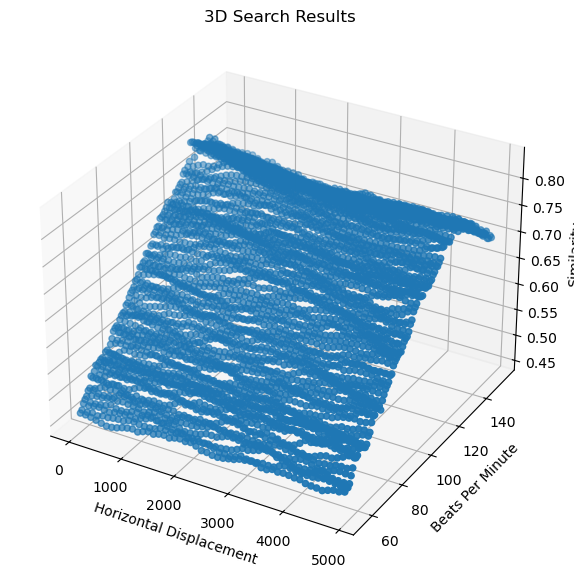

In [19]:
def plot_3d(x_data, y_data, z_data, title="3D Plot", xlabel="X", ylabel="Y", zlabel="Z"):
    """
    Plots 3D data using matplotlib
    
    Parameters:
    x_data, y_data, z_data: Arrays of data points
    title: Plot title (optional)
    xlabel, ylabel, zlabel: Axis labels (optional)
    """
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')
    
    ax.scatter(x_data, y_data, z_data)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_zlabel(zlabel)
    
    plt.show()
plot_3d(x_axis, y_axis, z_axis, title="3D Search Results", xlabel="Horizontal Displacement", ylabel="Beats Per Minute", zlabel="Similarity")


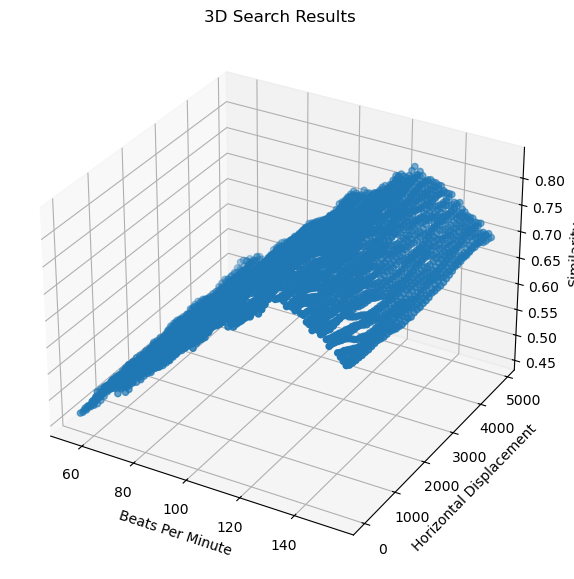

In [20]:
plot_3d(y_axis, x_axis, z_axis, title="3D Search Results", xlabel="Beats Per Minute", ylabel="Horizontal Displacement", zlabel="Similarity") 

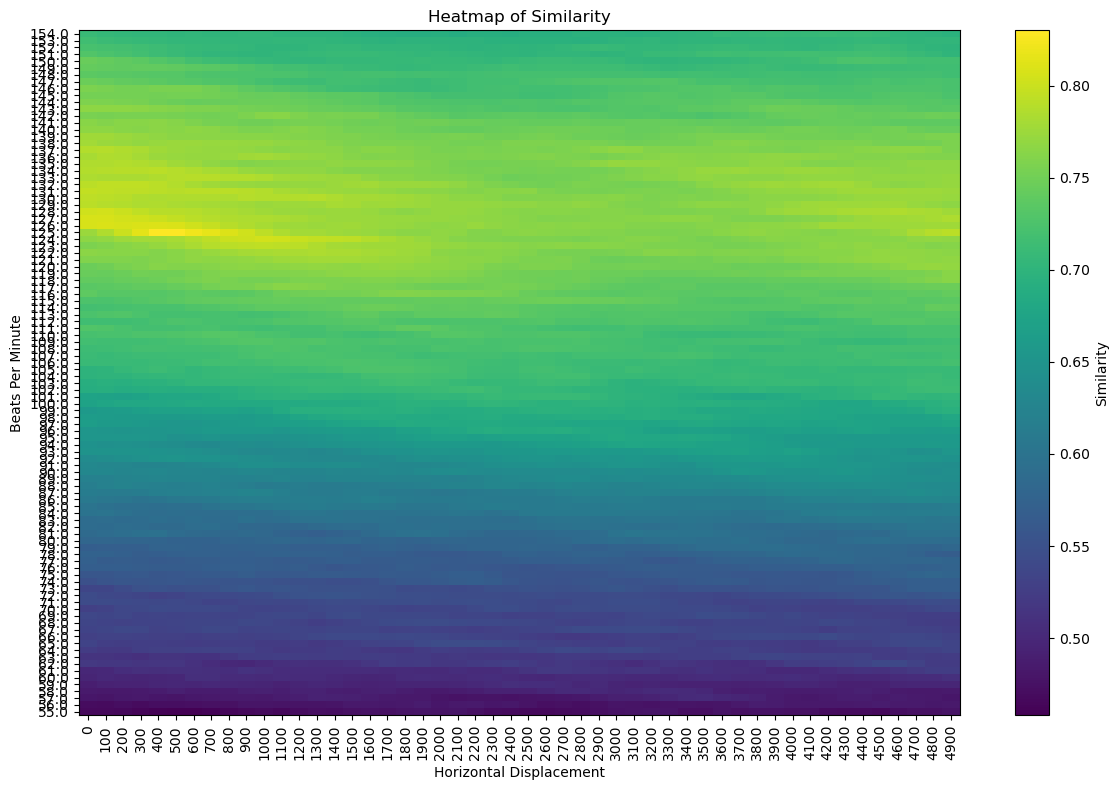

In [21]:
# Create a pivot table for the heatmap
heatmap_data = df.pivot_table(
    index='beat_per_minutes',
    columns='horizontal_displacement',
    values='similarity'
)

plt.figure(figsize=(12, 8))
plt.imshow(heatmap_data, aspect='auto', origin='lower', cmap='viridis')
plt.colorbar(label='Similarity')
plt.xlabel('Horizontal Displacement')
plt.ylabel('Beats Per Minute')
plt.title('Heatmap of Similarity')
plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns,
    rotation=90
)
plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=np.round(heatmap_data.index, 1)
)
plt.tight_layout()
plt.show()